# 🚨 Risk Alert Classifier — Early-Warning System for High-Risk Banking Customers

## Part A: Conceptual Understanding (Theory)

**Q1. What is Logistic Regression and why is it suitable for classification?**

**Answer:** Logistic Regression is a supervised algorithm that passes a weighted sum of the features through the **sigmoid function**, `P(y=1|x) = 1 / (1 + e^-(w·x + b))`, to produce a probability between 0 and 1. That probability is converted into a class using a threshold (default 0.5). It suits classification because the output is a bounded probability (a usable *risk score*), it trains fast, and its coefficients are easy to interpret.

**Q2. Explain classification performance metrics and why accuracy alone is insufficient.**

**Answer:** Classification metrics (Accuracy, Precision, Recall, F1-Score, AUC-ROC) are all derived from the **confusion matrix** (TP, TN, FP, FN) and describe different kinds of correctness. Accuracy alone is misleading on imbalanced data: if only ~12% of customers are high-risk, a model that predicts *"Low Risk"* for everyone is ~88% accurate while catching **zero** risky customers.

**Q3. Define Type-I Error and Type-II Error in the context of risk prediction.**

**Answer:**
- **Type-I Error (False Positive):** a *low-risk* customer is flagged as *high-risk*. Cost: unnecessary reviews and customer friction.
- **Type-II Error (False Negative):** a *high-risk* customer is predicted as *low-risk* and goes undetected. Cost: real default or fraud loss. For this bank, Type-II errors are the more expensive mistake.

**Q4. Explain Precision, Recall, F1-Score, TPR, and FPR.**

**Answer:**
- **Precision** = `TP / (TP + FP)` → of all customers flagged high-risk, how many truly are.
- **Recall = TPR** (True Positive Rate) = `TP / (TP + FN)` → of all truly high-risk customers, how many we caught.
- **F1-Score** = `2 × (Precision × Recall) / (Precision + Recall)` → harmonic mean balancing both.
- **FPR** (False Positive Rate) = `FP / (FP + TN)` → share of low-risk customers wrongly flagged.

**Q5. What is AUC-ROC and how does it help in evaluating classifiers?**

**Answer:** The **ROC curve** plots TPR against FPR at every possible decision threshold, and **AUC** is the area under it (0.5 = random guessing, 1.0 = perfect). It equals the probability that a randomly chosen high-risk customer gets a higher score than a randomly chosen low-risk one, so it compares models **independently of the threshold**.

**Q6. Why does imbalanced data create problems in classification models?**

**Answer:** With very few minority examples, the model can minimise its overall error by simply favouring the majority class. The result is a high accuracy but a **low recall for the minority class**, and a decision boundary biased toward the majority. It is fixed with resampling (under-sampling, over-sampling, SMOTE, ADASYN), class weights, and by judging models on Recall, F1 and AUC instead of accuracy.

## Part B: Dataset Understanding & Preparation

### Import Libraries

In [3]:
import warnings
import json
import pickle
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    make_scorer,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

# imblearn Pipeline = sklearn Pipeline + support for samplers (resampling only happens while fitting)
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

np.random.seed(42)
warnings.filterwarnings('ignore')

### Load Dataset

In [4]:
# Keep the CSV in the same folder as this notebook (or change the path)
DATA_PATH = Path('Risk_Alert_Classifier_Dataset_4600 - Risk_Alert_Classifier_Dataset_4600.csv.csv')

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head()

Shape: (4600, 19)


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [5]:
df.info()
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

,count,mean,std,min,25%,50%,75%,max
customer_id,4600.0,502300.500000,1328.049949,500001.000,501150.750,502300.50,503450.250,504600.000
age,4460.0,36.360314,10.670375,18.000,28.000,36.00,44.000,75.000
annual_income_inr,4434.0,41753.518268,17740.750972,15000.000,28980.000,38932.50,51282.500,163002.000
credit_score,4384.0,677.784443,64.888787,405.000,638.000,682.00,721.250,850.000
credit_utilization_ratio,4453.0,0.394721,0.205771,0.002,0.232,0.37,0.531,0.978
missed_payments_12m,4600.0,0.924130,1.300018,0.000,0.000,1.00,1.000,10.000
avg_late_payment_days,4600.0,5.538696,5.624891,0.100,2.100,3.90,6.600,47.100
monthly_transaction_count,4600.0,65.030000,24.180762,5.000,49.000,65.00,81.000,153.000
monthly_spend_inr,4471.0,21511.273541,10887.272864,3769.000,13422.500,19317.00,27147.000,87389.000
cash_advance_count_6m,4600.0,0.709783,1.020507,0.000,0.000,0.00,1.000,7.000


### Step 7 - Identify Input Features and Target Variable

In [6]:
TARGET = 'risk_status'                                   # 0 → Low Risk, 1 → High Risk
DROP_COLS = ['customer_id', 'last_transaction_date']     # identifier + raw date (no predictive signal)

categorical_features = ['gender', 'region', 'employment_type']
numeric_features = [
    col for col in df.columns
    if col not in categorical_features + DROP_COLS + [TARGET]
]

X = df[numeric_features + categorical_features]
y = df[TARGET]

feature_summary = pd.DataFrame({
    'Feature': X.columns,
    'Type': ['Numeric' if col in numeric_features else 'Categorical' for col in X.columns],
    'Missing Values': X.isnull().sum().values
})
display(feature_summary)

print("Target Variable :", TARGET)
print("Class Counts    :", Counter(y.tolist()))
print(f"High-Risk share : {y.mean():.2%}")

,Feature,Type,Missing Values
0,age,Numeric,140
1,annual_income_inr,Numeric,166
2,credit_score,Numeric,216
3,credit_utilization_ratio,Numeric,147
4,missed_payments_12m,Numeric,0
5,avg_late_payment_days,Numeric,0
6,monthly_transaction_count,Numeric,0
7,monthly_spend_inr,Numeric,129
8,cash_advance_count_6m,Numeric,0
9,complaints_last_6m,Numeric,0


Target Variable : risk_status
Class Counts    : Counter({0: 4043, 1: 557})
High-Risk share : 12.11%


**📝 Interpretation:** The data has 4,600 customers with 13 numeric and 3 categorical features. Only **12.11% (557)** are high-risk, so the target is clearly imbalanced. `customer_id` (an identifier) and `last_transaction_date` (a raw date with no relationship to risk) are dropped.

### Step 8 - Train-Test Split (Maintaining Class Distribution)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

distribution_check = pd.DataFrame({
    'Full Data': y.value_counts(normalize=True),
    'Train': y_train.value_counts(normalize=True),
    'Test': y_test.value_counts(normalize=True)
}).round(4)
distribution_check.index = ['Low Risk (0)', 'High Risk (1)']
display(distribution_check)

Train shape: (3680, 16)
Test shape : (920, 16)


,Full Data,Train,Test
Low Risk (0),0.8789,0.8788,0.8793
High Risk (1),0.1211,0.1212,0.1207


**📝 Interpretation:** Stratification kept the class ratio at ~12.1% high-risk in the full data, the train set (3,680 rows) and the test set (920 rows). The test set holds 111 high-risk customers and is never resampled.

### Step 9 - Identify Missing Values and Apply KNN Imputer

,Missing Count,Missing %
credit_score,181,4.92
annual_income_inr,132,3.59
credit_utilization_ratio,118,3.21
age,116,3.15
employment_type,115,3.12
monthly_spend_inr,110,2.99
region,78,2.12


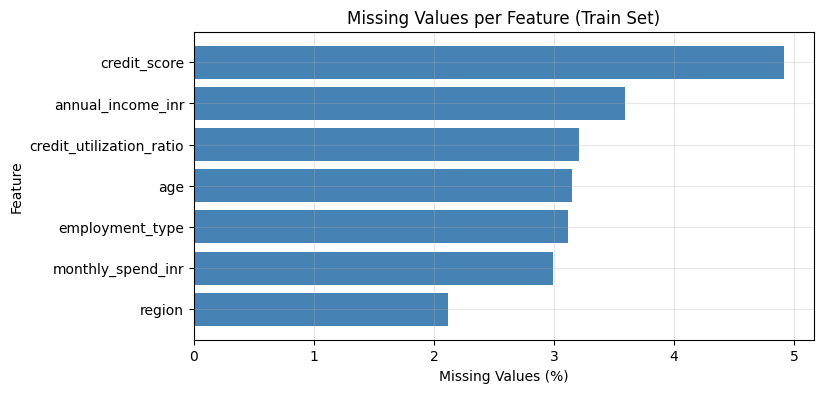

In [8]:
missing_report = pd.DataFrame({
    'Missing Count': X_train.isnull().sum(),
    'Missing %': (X_train.isnull().mean() * 100).round(2)
})
missing_report = missing_report[missing_report['Missing Count'] > 0].sort_values('Missing %', ascending=False)
display(missing_report)

plt.figure(figsize=(8, 4))
plt.barh(missing_report.index, missing_report['Missing %'], color='steelblue')
plt.xlabel('Missing Values (%)')
plt.ylabel('Feature')
plt.title('Missing Values per Feature (Train Set)')
plt.gca().invert_yaxis()
plt.grid(alpha=0.3)
plt.show()

**📝 Interpretation:** Seven features contain missing values, from 2.1% (`region`) up to 4.9% (`credit_score`). The gaps are small but spread over many columns, so dropping rows would waste a lot of data; imputation is the better choice.

In [9]:
# Numeric   : scale first, then KNN-impute (KNN is distance-based, so unscaled income/spend would dominate;
#             StandardScaler ignores NaN while fitting, so this order is safe)
# Categorical: most-frequent imputation + One-Hot Encoding (KNN cannot work on text)
numeric_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('imputer', KNNImputer(n_neighbors=5))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# Fit on TRAIN only → transform both (no information leaks from the test set)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
feature_names_prep = preprocessor.get_feature_names_out()

print("Train prepared shape:", X_train_prep.shape)
print("Test prepared shape :", X_test_prep.shape)
print("Missing after prep (train):", np.isnan(X_train_prep).sum())
print("Missing after prep (test) :", np.isnan(X_test_prep).sum())

Train prepared shape: (3680, 26)
Test prepared shape : (920, 26)
Missing after prep (train): 0
Missing after prep (test) : 0


In [10]:
# Verify KNN imputation: bring the imputed numeric data back to the original scale and compare
fitted_numeric = preprocessor.named_transformers_['numeric']

X_train_num_imputed = pd.DataFrame(
    fitted_numeric.named_steps['scaler'].inverse_transform(fitted_numeric.transform(X_train[numeric_features])),
    columns=numeric_features,
    index=X_train.index
)

cols_with_missing = [col for col in missing_report.index if col in numeric_features]

imputation_check = pd.DataFrame({
    'Missing Before': X_train[cols_with_missing].isnull().sum(),
    'Missing After': X_train_num_imputed[cols_with_missing].isnull().sum(),
    'Mean Before': X_train[cols_with_missing].mean().round(3),
    'Mean After': X_train_num_imputed[cols_with_missing].mean().round(3)
})
display(imputation_check)

,Missing Before,Missing After,Mean Before,Mean After
credit_score,181,0,677.596,677.635
annual_income_inr,132,0,41923.632,41863.235
credit_utilization_ratio,118,0,0.393,0.393
age,116,0,36.307,36.308
monthly_spend_inr,110,0,21618.357,21582.945


**📝 Interpretation:** No missing values remain after preprocessing (0 in train and test). The means barely move (e.g. `credit_score` 677.60 → 677.64), so KNN imputation filled the gaps without distorting the distributions.

## Part C: Baseline Classification Model

### Step 10 - Logistic Regression Baseline

In [11]:
lr_baseline = LogisticRegression(max_iter=1000, random_state=42)
lr_baseline.fit(X_train_prep, y_train)

y_pred_base = lr_baseline.predict(X_test_prep)
y_prob_base = lr_baseline.predict_proba(X_test_prep)[:, 1]

print("Baseline Logistic Regression trained successfully")

Baseline Logistic Regression trained successfully


### Step 11 - Confusion Matrix, Accuracy, Precision, Recall, F1-Score

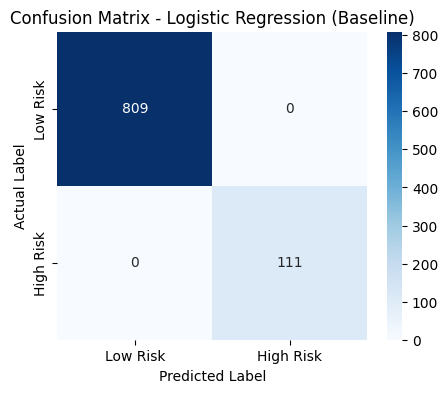

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0

              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



In [12]:
f2_scorer = make_scorer(fbeta_score, beta=2)    # recall-weighted score (missing a risky customer costs more)
class_labels = ['Low Risk', 'High Risk']

model_results = []   # one dict per model → final comparison table
roc_store = {}       # model name → predicted probabilities (used for ROC curves in Part G)


def store_result(model_name, y_true, y_pred, y_prob):
    """Compute all test metrics for one model and save them for later comparison"""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    model_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'F2-Score': fbeta_score(y_true, y_pred, beta=2),
        'AUC-ROC': roc_auc_score(y_true, y_prob),
        'FP (Type-I)': fp,
        'FN (Type-II)': fn
    })
    roc_store[model_name] = y_prob


def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.title(title)
    plt.show()


cm = confusion_matrix(y_test, y_pred_base)
plot_confusion_matrix(cm, 'Confusion Matrix - Logistic Regression (Baseline)')

print("Accuracy :", round(accuracy_score(y_test, y_pred_base), 4))
print("Precision:", round(precision_score(y_test, y_pred_base), 4))
print("Recall   :", round(recall_score(y_test, y_pred_base), 4))
print("F1-Score :", round(f1_score(y_test, y_pred_base), 4))
print()
print(classification_report(y_test, y_pred_base, target_names=class_labels))

store_result('Logistic Regression (Baseline)', y_test, y_pred_base, y_prob_base)

**📝 Interpretation:** The baseline Logistic Regression scores **100% on every metric** on the test set (809 TN, 111 TP, no errors). That is unusually strong and tells us the risk classes are almost linearly separable in this dataset. The cross-validation in Step 15 gives a more cautious estimate (recall ≈ 97.3%).

### Step 12 - Identify Type-I and Type-II Errors

In [13]:
tn, fp, fn, tp = cm.ravel()

print(f"True Negatives  (Low Risk → predicted Low Risk)    : {tn}")
print(f"False Positives (Low Risk → predicted High Risk)   : {fp}   ← Type-I Error")
print(f"False Negatives (High Risk → predicted Low Risk)   : {fn}   ← Type-II Error")
print(f"True Positives  (High Risk → predicted High Risk)  : {tp}")

# Manual formulas, then verify against sklearn
manual_precision = tp / (tp + fp) if (tp + fp) > 0 else 0
manual_recall = tp / (tp + fn)
manual_fpr = fp / (fp + tn)

print()
print("Manual Precision:", round(manual_precision, 4), "| matches sklearn:", np.isclose(manual_precision, precision_score(y_test, y_pred_base)))
print("Manual Recall/TPR:", round(manual_recall, 4), "| matches sklearn:", np.isclose(manual_recall, recall_score(y_test, y_pred_base)))
print("Manual FPR       :", round(manual_fpr, 4))

True Negatives  (Low Risk → predicted Low Risk)    : 809
False Positives (Low Risk → predicted High Risk)   : 0   ← Type-I Error
False Negatives (High Risk → predicted Low Risk)   : 0   ← Type-II Error
True Positives  (High Risk → predicted High Risk)  : 111

Manual Precision: 1.0 | matches sklearn: True
Manual Recall/TPR: 1.0 | matches sklearn: True
Manual FPR       : 0.0


**📝 Interpretation:** Type-I errors (FP) = **0** and Type-II errors (FN) = **0**: no safe customer was flagged and no risky customer was missed. The manual precision, recall and FPR match sklearn, which confirms the confusion matrix was read correctly.

## Part D: Handling Imbalanced Data

### Step 13 - Impact of Class Imbalance on Model Performance

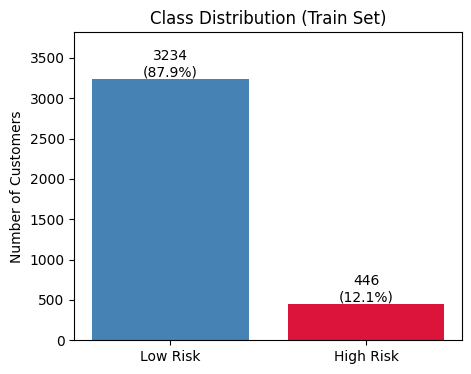

,Model,Accuracy,Recall (High Risk),F1 (High Risk)
0,Dummy (always Low Risk),0.8793,0.0,0.0
1,Logistic Regression (Baseline),1.0000,1.0,1.0


In [14]:
class_counts = y_train.value_counts().sort_index()

plt.figure(figsize=(5, 4))
bars = plt.bar(class_labels, class_counts.values, color=['steelblue', 'crimson'])
for bar, count in zip(bars, class_counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, count, f"{count}\n({count / class_counts.sum():.1%})", ha='center', va='bottom')
plt.ylabel('Number of Customers')
plt.title('Class Distribution (Train Set)')
plt.ylim(0, class_counts.max() * 1.18)
plt.show()

# Accuracy paradox: a "model" that always predicts Low Risk
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_prep, y_train)
dummy_pred = dummy.predict(X_test_prep)

accuracy_paradox = pd.DataFrame({
    'Model': ['Dummy (always Low Risk)', 'Logistic Regression (Baseline)'],
    'Accuracy': [accuracy_score(y_test, dummy_pred), accuracy_score(y_test, y_pred_base)],
    'Recall (High Risk)': [recall_score(y_test, dummy_pred), recall_score(y_test, y_pred_base)],
    'F1 (High Risk)': [f1_score(y_test, dummy_pred), f1_score(y_test, y_pred_base)]
}).round(4)
display(accuracy_paradox)

**📝 Interpretation:** A dummy model that always predicts *Low Risk* reaches **87.9% accuracy** but catches **0%** of high-risk customers. This is the accuracy paradox: accuracy hides the minority class, so recall and F1 of the high-risk class are the metrics that matter.

,Minority Kept,High-Risk Share in Train,Recall (High Risk),Precision (High Risk),F1 (High Risk),Missed High-Risk (FN)
0,100%,0.1212,1.000,1.0,1.0000,0
1,50%,0.0645,1.000,1.0,1.0000,0
2,25%,0.0332,0.991,1.0,0.9955,1
3,10%,0.0134,0.991,1.0,0.9955,1


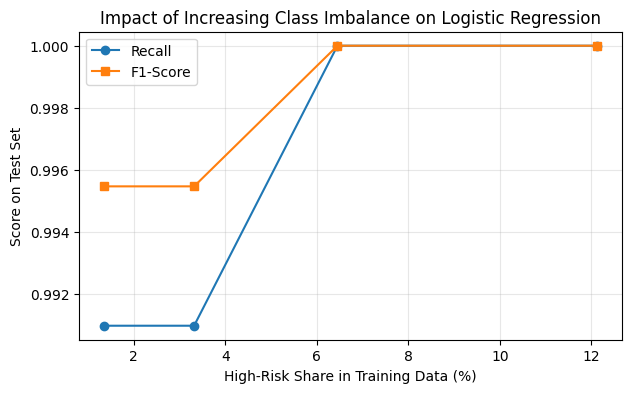

In [15]:
# Shrink the minority class in the TRAIN data only (test set untouched) and watch the baseline degrade
rng = np.random.RandomState(42)
minority_idx = np.where(y_train.values == 1)[0]
majority_idx = np.where(y_train.values == 0)[0]

imbalance_rows = []
for keep_fraction in [1.0, 0.5, 0.25, 0.10]:
    kept_minority = rng.choice(minority_idx, size=int(len(minority_idx) * keep_fraction), replace=False)
    subset_idx = np.concatenate([majority_idx, kept_minority])

    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_train_prep[subset_idx], y_train.values[subset_idx])
    pred = model.predict(X_test_prep)

    imbalance_rows.append({
        'Minority Kept': f"{keep_fraction:.0%}",
        'High-Risk Share in Train': len(kept_minority) / len(subset_idx),
        'Recall (High Risk)': recall_score(y_test, pred),
        'Precision (High Risk)': precision_score(y_test, pred, zero_division=0),
        'F1 (High Risk)': f1_score(y_test, pred),
        'Missed High-Risk (FN)': int(((pred == 0) & (y_test.values == 1)).sum())
    })

imbalance_impact = pd.DataFrame(imbalance_rows)
display(imbalance_impact.round(4))

plt.figure(figsize=(7, 4))
plt.plot(imbalance_impact['High-Risk Share in Train'] * 100, imbalance_impact['Recall (High Risk)'], marker='o', label='Recall')
plt.plot(imbalance_impact['High-Risk Share in Train'] * 100, imbalance_impact['F1 (High Risk)'], marker='s', label='F1-Score')
plt.xlabel('High-Risk Share in Training Data (%)')
plt.ylabel('Score on Test Set')
plt.title('Impact of Increasing Class Imbalance on Logistic Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**📝 Interpretation:** Cutting the high-risk share in training from 12.1% to 1.3% lowers recall only from 1.000 to 0.991 (the first missed customer appears at 3.3%). Logistic Regression is robust here because the classes are well separated; on noisier real-world data the drop would be larger.

### Step 14 - Apply Under-Sampling, Over-Sampling, SMOTE and ADASYN

Original        → Counter({0: 3234, 1: 446})
Under-Sampling  → Counter({0: 446, 1: 446})
Over-Sampling   → Counter({0: 3234, 1: 3234})
SMOTE           → Counter({0: 3234, 1: 3234})
ADASYN          → Counter({1: 3247, 0: 3234})


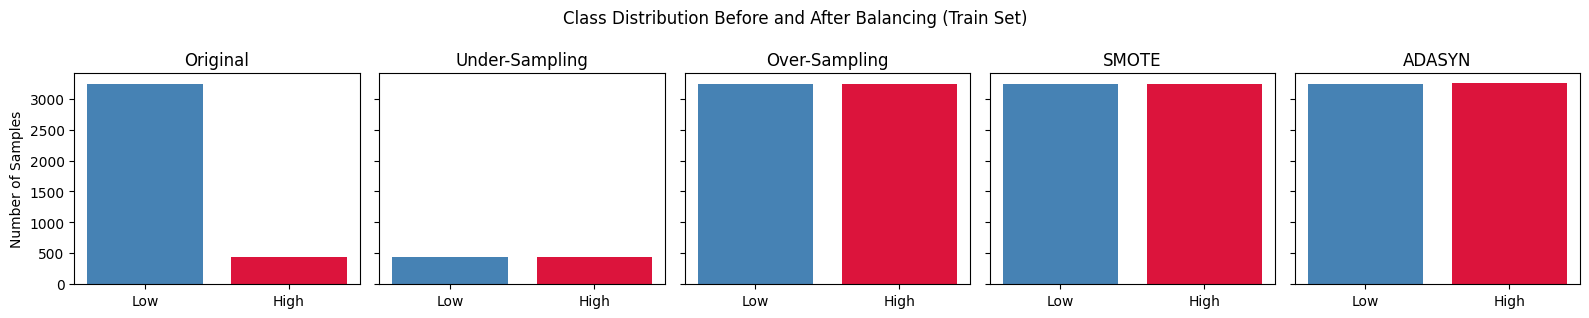

In [16]:
samplers = {
    'Under-Sampling': RandomUnderSampler(random_state=42),
    'Over-Sampling': RandomOverSampler(random_state=42),
    'SMOTE': SMOTE(random_state=42),
    'ADASYN': ADASYN(random_state=42)
}

# Resample the TRAIN set only (the test set always stays in its real, imbalanced form)
balanced_data = {}
print(f"{'Original':15s} →", Counter(y_train.tolist()))

for technique, sampler in samplers.items():
    X_bal, y_bal = sampler.fit_resample(X_train_prep, y_train)
    balanced_data[technique] = (X_bal, y_bal)
    print(f"{technique:15s} →", Counter(np.asarray(y_bal).tolist()))

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
all_sets = {'Original': y_train, **{name: data[1] for name, data in balanced_data.items()}}
for ax, (name, labels) in zip(axes, all_sets.items()):
    counts = pd.Series(np.asarray(labels)).value_counts().sort_index()
    ax.bar(['Low', 'High'], counts.values, color=['steelblue', 'crimson'])
    ax.set_title(name)
axes[0].set_ylabel('Number of Samples')
fig.suptitle('Class Distribution Before and After Balancing (Train Set)')
plt.tight_layout()
plt.show()

**📝 Interpretation:** Under-sampling shrinks the train set to 446 + 446 rows (it throws away 2,788 safe customers). Over-sampling and SMOTE grow the minority class to 3,234 (duplicated vs synthetic points). ADASYN ends with 3,247 high-risk vs 3,234 low-risk rows because it adds more points near hard-to-classify customers.

In [17]:
# Retrain Logistic Regression on every balanced training set and evaluate on the SAME untouched test set
for technique, (X_bal, y_bal) in balanced_data.items():
    lr_bal = LogisticRegression(max_iter=1000, random_state=42)
    lr_bal.fit(X_bal, y_bal)

    pred = lr_bal.predict(X_test_prep)
    prob = lr_bal.predict_proba(X_test_prep)[:, 1]
    store_result(f'Logistic Regression + {technique}', y_test, pred, prob)

print("All four balanced models trained and evaluated")

All four balanced models trained and evaluated


### Step 15 - Compare Performance Before and After Balancing

,Model,Recall,F1-Score,AUC-ROC,Precision,FP (Type-I),FN (Type-II)
0,Logistic Regression (Baseline),1.0,1.0000,1.0,1.0000,0,0
1,Logistic Regression + Under-Sampling,1.0,0.9867,1.0,0.9737,3,0
2,Logistic Regression + Over-Sampling,1.0,0.9911,1.0,0.9823,2,0
3,Logistic Regression + SMOTE,1.0,0.9911,1.0,0.9823,2,0
4,Logistic Regression + ADASYN,1.0,0.9867,1.0,0.9737,3,0


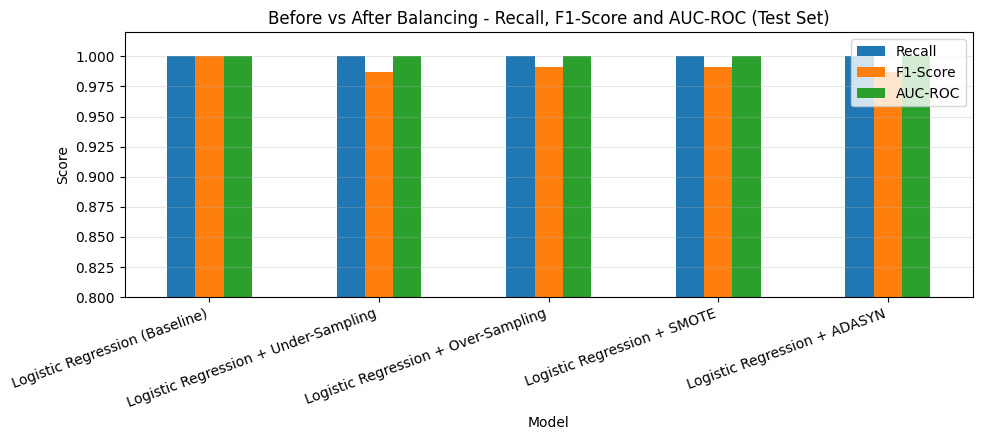

In [18]:
results_df = pd.DataFrame(model_results)

balancing_names = ['Logistic Regression (Baseline)'] + [f'Logistic Regression + {name}' for name in samplers]
balancing_compare = results_df[results_df['Model'].isin(balancing_names)][
    ['Model', 'Recall', 'F1-Score', 'AUC-ROC', 'Precision', 'FP (Type-I)', 'FN (Type-II)']
].reset_index(drop=True)
display(balancing_compare.round(4))

balancing_compare.set_index('Model')[['Recall', 'F1-Score', 'AUC-ROC']].plot(kind='bar', figsize=(10, 4.5), ylim=(0.8, 1.02))
plt.ylabel('Score')
plt.title('Before vs After Balancing - Recall, F1-Score and AUC-ROC (Test Set)')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**📝 Interpretation:** On the test set every technique keeps Recall = 1.0 and AUC = 1.0, while F1 slips slightly (0.987-0.991 vs 1.000) because balancing adds 2-3 false positives. With only 111 high-risk customers, the test set cannot really separate these techniques, so the next cell uses cross-validation.

In [19]:
# The test set is small (111 high-risk customers) → choose the technique with 5-fold CV on TRAIN data.
# The sampler sits INSIDE the CV pipeline, so synthetic samples never leak into validation folds.
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scoring = {'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'f2': f2_scorer, 'roc_auc': 'roc_auc'}

sampler_cv_rows = []

cv_baseline = cross_validate(
    Pipeline([('model', LogisticRegression(max_iter=1000, random_state=42))]),
    X_train_prep, y_train, cv=cv_strategy, scoring=cv_scoring
)
sampler_cv_rows.append({
    'Technique': 'None (Baseline)',
    'CV Recall': cv_baseline['test_recall'].mean(),
    'CV Precision': cv_baseline['test_precision'].mean(),
    'CV F1': cv_baseline['test_f1'].mean(),
    'CV F2': cv_baseline['test_f2'].mean()
})

for technique, sampler in samplers.items():
    sampler_pipeline = Pipeline([
        ('sampler', clone(sampler)),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ])
    cv_scores = cross_validate(sampler_pipeline, X_train_prep, y_train, cv=cv_strategy, scoring=cv_scoring)
    sampler_cv_rows.append({
        'Technique': technique,
        'CV Recall': cv_scores['test_recall'].mean(),
        'CV Precision': cv_scores['test_precision'].mean(),
        'CV F1': cv_scores['test_f1'].mean(),
        'CV F2': cv_scores['test_f2'].mean()
    })

sampler_cv = pd.DataFrame(sampler_cv_rows)

# Best technique = highest CV F2 among the four sampling techniques (recall-weighted, business-driven)
sampling_only = sampler_cv[sampler_cv['Technique'].isin(samplers.keys())]
best_sampler_name = sampling_only.loc[sampling_only['CV F2'].idxmax(), 'Technique']
sampler_cv['Selected'] = np.where(sampler_cv['Technique'] == best_sampler_name, '⭐', '')
display(sampler_cv.round(4))

X_train_bal, y_train_bal = balanced_data[best_sampler_name]
print(f"\n🎯 Best balancing technique (CV F2): {best_sampler_name}")
print("Balanced train class counts:", Counter(np.asarray(y_train_bal).tolist()))

,Technique,CV Recall,CV Precision,CV F1,CV F2,Selected
0,None (Baseline),0.9732,0.9933,0.9830,0.9770,
1,Under-Sampling,0.9866,0.9425,0.9638,0.9773,
2,Over-Sampling,0.9866,0.9551,0.9703,0.9799,⭐
3,SMOTE,0.9844,0.9633,0.9734,0.9799,
4,ADASYN,0.9888,0.9310,0.9588,0.9765,



🎯 Best balancing technique (CV F2): Over-Sampling
Balanced train class counts: Counter({0: 3234, 1: 3234})


**📝 Interpretation:** Cross-validation (sampler inside each fold) is more informative: every technique raises recall (97.3% → 98.4-98.9%) at the cost of precision (99.3% → 93.1-96.3%). Over-Sampling and SMOTE tie on CV F2 (0.9799 at 4 decimals); Over-Sampling is marginally ahead and is carried into Parts E and F.

## Part E: Tree-Based Classification Models

### Step 16 - Decision Tree Classifier

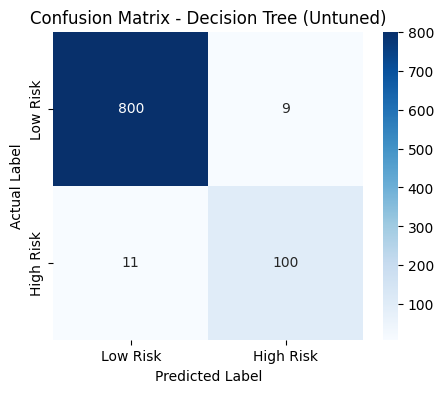

              precision    recall  f1-score   support

    Low Risk       0.99      0.99      0.99       809
   High Risk       0.92      0.90      0.91       111

    accuracy                           0.98       920
   macro avg       0.95      0.94      0.95       920
weighted avg       0.98      0.98      0.98       920

Tree depth : 16
Leaf nodes : 73


In [20]:
# Tree models are trained on the balanced train set chosen in Step 15
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_bal, y_train_bal)

y_pred_dt = dt_model.predict(X_test_prep)
y_prob_dt = dt_model.predict_proba(X_test_prep)[:, 1]

plot_confusion_matrix(confusion_matrix(y_test, y_pred_dt), 'Confusion Matrix - Decision Tree (Untuned)')
print(classification_report(y_test, y_pred_dt, target_names=class_labels))

store_result('Decision Tree (Untuned)', y_test, y_pred_dt, y_prob_dt)

print("Tree depth :", dt_model.get_depth())
print("Leaf nodes :", dt_model.get_n_leaves())

**📝 Interpretation:** The unpruned Decision Tree grows to depth 16 with 73 leaves and reaches only **90.1% recall** on the test set, with 11 missed high-risk customers (Type-II) and 9 false alarms (Type-I).

### Step 17 - Analyze Overfitting (Training vs Testing Performance)

,Accuracy,Recall,F1-Score,AUC-ROC
Train,1.0000,1.0000,1.0000,1.0000
Test,0.9783,0.9009,0.9091,0.9449


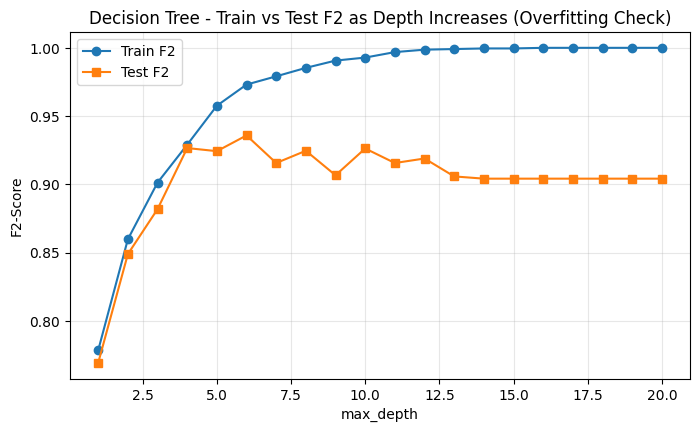

In [21]:
def split_scores(model, X_tr, y_tr, X_te, y_te):
    """Return Recall / F1 / AUC on the real (imbalanced) train and test sets"""
    rows = {}
    for label, X_, y_ in [('Train', X_tr, y_tr), ('Test', X_te, y_te)]:
        pred = model.predict(X_)
        prob = model.predict_proba(X_)[:, 1]
        rows[label] = {
            'Accuracy': accuracy_score(y_, pred),
            'Recall': recall_score(y_, pred),
            'F1-Score': f1_score(y_, pred),
            'AUC-ROC': roc_auc_score(y_, prob)
        }
    return pd.DataFrame(rows).T


dt_split = split_scores(dt_model, X_train_prep, y_train, X_test_prep, y_test)
display(dt_split.round(4))

# Depth sweep: train vs test F2 as the tree grows
depths = list(range(1, 21))
train_f2_scores, test_f2_scores = [], []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train_bal, y_train_bal)
    train_f2_scores.append(fbeta_score(y_train, tree.predict(X_train_prep), beta=2))
    test_f2_scores.append(fbeta_score(y_test, tree.predict(X_test_prep), beta=2))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_f2_scores, marker='o', label='Train F2')
plt.plot(depths, test_f2_scores, marker='s', label='Test F2')
plt.xlabel('max_depth')
plt.ylabel('F2-Score')
plt.title('Decision Tree - Train vs Test F2 as Depth Increases (Overfitting Check)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**📝 Interpretation:** Train scores are 1.000 while test recall falls to 0.901 and AUC to 0.945: a clear overfitting gap. The depth sweep shows test F2 peaking near depth 6 (≈ 0.94) and then dropping to ≈ 0.90, while train F2 keeps climbing to 1.0.

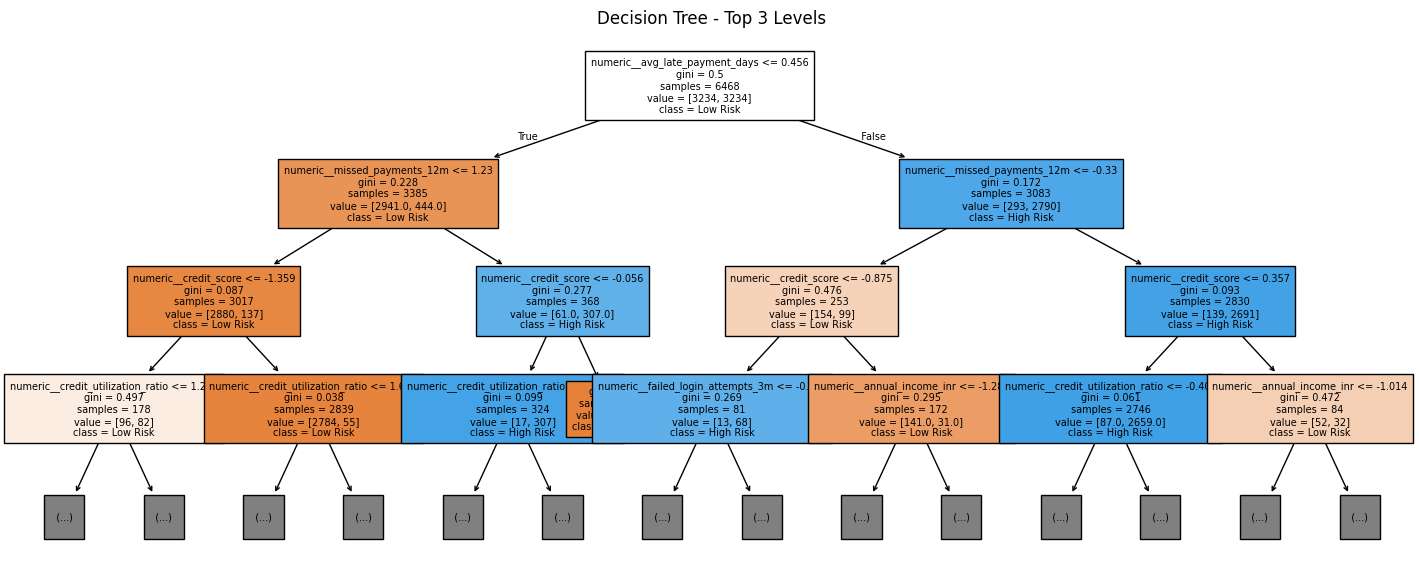

In [22]:
# Top 3 levels of the fitted tree (readable view of the first decisions)
plt.figure(figsize=(18, 7))
plot_tree(dt_model, max_depth=3, feature_names=feature_names_prep, class_names=class_labels, filled=True, fontsize=7)
plt.title('Decision Tree - Top 3 Levels')
plt.show()

### Step 18 - Random Forest Classifier

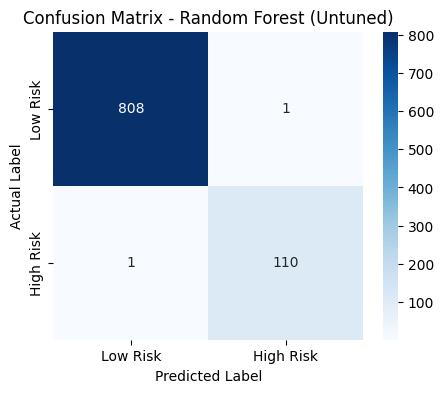

              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       0.99      0.99      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      0.99      0.99       920
weighted avg       1.00      1.00      1.00       920



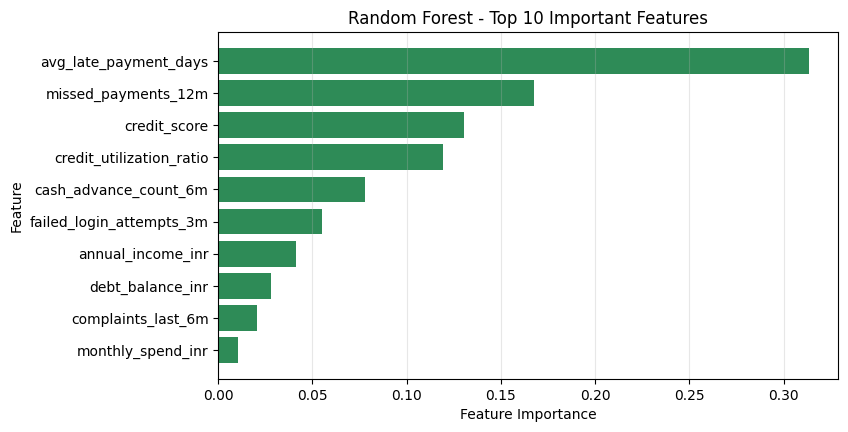

In [23]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train_bal, y_train_bal)

y_pred_rf = rf_model.predict(X_test_prep)
y_prob_rf = rf_model.predict_proba(X_test_prep)[:, 1]

plot_confusion_matrix(confusion_matrix(y_test, y_pred_rf), 'Confusion Matrix - Random Forest (Untuned)')
print(classification_report(y_test, y_pred_rf, target_names=class_labels))

store_result('Random Forest (Untuned)', y_test, y_pred_rf, y_prob_rf)

rf_importance = pd.DataFrame({
    'Feature': feature_names_prep,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(8, 4.5))
plt.barh(rf_importance['Feature'].str.replace('numeric__', '').str.replace('categorical__', ''), rf_importance['Importance'], color='seagreen')
plt.gca().invert_yaxis()
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest - Top 10 Important Features')
plt.grid(axis='x', alpha=0.3)
plt.show()

**📝 Interpretation:** Random Forest removes most of the tree's weakness: recall 99.1%, precision 99.1%, AUC 0.9999, with only 1 FN and 1 FP. The most important features are `avg_late_payment_days`, `missed_payments_12m`, `credit_score` and `credit_utilization_ratio`, i.e. repayment behaviour, which is exactly what a risk model should rely on.

### Step 19 - Compare Decision Tree vs Random Forest

In [24]:
rf_split = split_scores(rf_model, X_train_prep, y_train, X_test_prep, y_test)

tree_vs_forest = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Train F1': [dt_split.loc['Train', 'F1-Score'], rf_split.loc['Train', 'F1-Score']],
    'Test F1': [dt_split.loc['Test', 'F1-Score'], rf_split.loc['Test', 'F1-Score']],
    'Test Accuracy': [dt_split.loc['Test', 'Accuracy'], rf_split.loc['Test', 'Accuracy']],
    'Test Recall': [dt_split.loc['Test', 'Recall'], rf_split.loc['Test', 'Recall']],
    'Test AUC-ROC': [dt_split.loc['Test', 'AUC-ROC'], rf_split.loc['Test', 'AUC-ROC']]
})
tree_vs_forest['Generalization Gap (Train F1 - Test F1)'] = tree_vs_forest['Train F1'] - tree_vs_forest['Test F1']
display(tree_vs_forest.round(4))

,Model,Train F1,Test F1,Test Accuracy,Test Recall,Test AUC-ROC,Generalization Gap (Train F1 - Test F1)
0,Decision Tree,1.0,0.9091,0.9783,0.9009,0.9449,0.0909
1,Random Forest,1.0,0.9910,0.9978,0.9910,0.9999,0.0090


**📝 Interpretation:** Random Forest generalises far better: test F1 **0.991 vs 0.909**, and the train-test gap is only **0.009 vs 0.091**. Averaging many de-correlated trees cancels the overfitting of a single deep tree.

## Part F: Hyperparameter Tuning

### Step 20 - Randomized Search CV (Decision Tree and Random Forest)

In [25]:
# Sampler lives INSIDE the search pipeline → resampling is done on training folds only
base_sampler = samplers[best_sampler_name]

dt_pipeline = Pipeline([
    ('sampler', clone(base_sampler)),
    ('model', DecisionTreeClassifier(random_state=42))
])

dt_param_dist = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 4, 5, 6, 8, 10, 12, 15, None],
    'model__min_samples_split': [2, 5, 10, 20, 50],
    'model__min_samples_leaf': [1, 2, 4, 8, 16],
    'model__max_features': [None, 'sqrt', 'log2']
}

dt_random = RandomizedSearchCV(
    dt_pipeline,
    param_distributions=dt_param_dist,
    n_iter=25,
    cv=cv_strategy,
    scoring=f2_scorer,
    random_state=42,
    n_jobs=-1
)
dt_random.fit(X_train_prep, y_train)

print("Decision Tree - best params:", dt_random.best_params_)
print("Decision Tree - best CV F2 :", round(dt_random.best_score_, 4))

dt_tuned_pred = dt_random.best_estimator_.predict(X_test_prep)
dt_tuned_prob = dt_random.best_estimator_.predict_proba(X_test_prep)[:, 1]
store_result('Decision Tree (Tuned)', y_test, dt_tuned_pred, dt_tuned_prob)

Decision Tree - best params: {'model__min_samples_split': 5, 'model__min_samples_leaf': 16, 'model__max_features': None, 'model__max_depth': 15, 'model__criterion': 'entropy'}
Decision Tree - best CV F2 : 0.8911


In [26]:
rf_pipeline = Pipeline([
    ('sampler', clone(base_sampler)),
    ('model', RandomForestClassifier(random_state=42, n_jobs=1))
])

rf_param_dist = {
    'model__n_estimators': [100, 150, 200, 300],
    'model__max_depth': [4, 6, 8, 10, 12, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__max_features': ['sqrt', 'log2', 0.5]
}

rf_random = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=12,
    cv=cv_strategy,
    scoring=f2_scorer,
    random_state=42,
    n_jobs=-1
)
rf_random.fit(X_train_prep, y_train)

print("Random Forest - best params:", rf_random.best_params_)
print("Random Forest - best CV F2 :", round(rf_random.best_score_, 4))

rf_tuned_pred = rf_random.best_estimator_.predict(X_test_prep)
rf_tuned_prob = rf_random.best_estimator_.predict_proba(X_test_prep)[:, 1]
store_result('Random Forest (Tuned)', y_test, rf_tuned_pred, rf_tuned_prob)

Random Forest - best params: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 6}
Random Forest - best CV F2 : 0.9637


**📝 Interpretation:** Randomized Search (scored on F2, with the sampler inside each CV fold) gives the Decision Tree a CV F2 of 0.891 and the Random Forest a CV F2 of **0.964**. Tuning lifts the tree's test recall from 0.901 to 0.964 and the forest's to 1.000.

### Step 21 - Grid Search CV (Fine-Tuning the Best Performing Model)

In [27]:
def fine_grid(best_params, tunable):
    """Small grid around the Randomized Search winner: ±1 step on the chosen integer params, everything else fixed"""
    step = {'model__n_estimators': 50, 'model__max_depth': 2, 'model__min_samples_split': 3, 'model__min_samples_leaf': 1}
    lowest = {'model__n_estimators': 50, 'model__max_depth': 2, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1}
    grid = {}
    for param, value in best_params.items():
        if param in tunable and value is not None:
            grid[param] = sorted({max(lowest[param], value - step[param]), value, value + step[param]})
        else:
            grid[param] = [value]
    return grid


# Best performing model = higher CV F2 from Randomized Search (selected on TRAIN data only)
if rf_random.best_score_ >= dt_random.best_score_:
    best_family, best_random = 'Random Forest', rf_random
    tunable_params = ['model__n_estimators', 'model__max_depth', 'model__min_samples_leaf']
else:
    best_family, best_random = 'Decision Tree', dt_random
    tunable_params = ['model__max_depth', 'model__min_samples_split', 'model__min_samples_leaf']

print("Best performing family :", best_family)

fine_param_grid = fine_grid(best_random.best_params_, tunable_params)
print("Fine-tuning grid       :", fine_param_grid)

grid_search = GridSearchCV(
    clone(best_random.best_estimator_),
    param_grid=fine_param_grid,
    cv=cv_strategy,
    scoring=f2_scorer,
    n_jobs=-1
)
grid_search.fit(X_train_prep, y_train)

print("\nGrid Search best params:", grid_search.best_params_)
print("Grid Search best CV F2 :", round(grid_search.best_score_, 4))

grid_pred = grid_search.best_estimator_.predict(X_test_prep)
grid_prob = grid_search.best_estimator_.predict_proba(X_test_prep)[:, 1]
store_result(f'{best_family} (Grid-Tuned)', y_test, grid_pred, grid_prob)

Best performing family : Random Forest
Fine-tuning grid       : {'model__n_estimators': [150, 200, 250], 'model__min_samples_split': [5], 'model__min_samples_leaf': [1, 2], 'model__max_features': ['log2'], 'model__max_depth': [4, 6, 8]}

Grid Search best params: {'model__max_depth': 6, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 150}
Grid Search best CV F2 : 0.9637


**📝 Interpretation:** The Random Forest was the best performing family, so Grid Search explored 150-250 trees, depth 4-8 and leaf size 1-2 around its winner. The CV F2 stays at 0.9637 but with 150 trees instead of 200: the randomized search had already found a near-optimal region, so fine-tuning gave a lighter model rather than a better score.

### Step 22 - Compare Tuned vs Untuned Model Performance

,Model,Accuracy,Precision,Recall,F1-Score,F2-Score,AUC-ROC,FP (Type-I),FN (Type-II)
0,Decision Tree (Untuned),0.9783,0.9174,0.9009,0.9091,0.9042,0.9449,9,11
1,Decision Tree (Tuned),0.9728,0.8359,0.9640,0.8954,0.9353,0.9847,21,4
2,Random Forest (Untuned),0.9978,0.9910,0.9910,0.9910,0.9910,0.9999,1,1
3,Random Forest (Tuned),0.9946,0.9569,1.0000,0.9780,0.9911,0.9999,5,0
4,Random Forest (Grid-Tuned),0.9946,0.9569,1.0000,0.9780,0.9911,1.0000,5,0


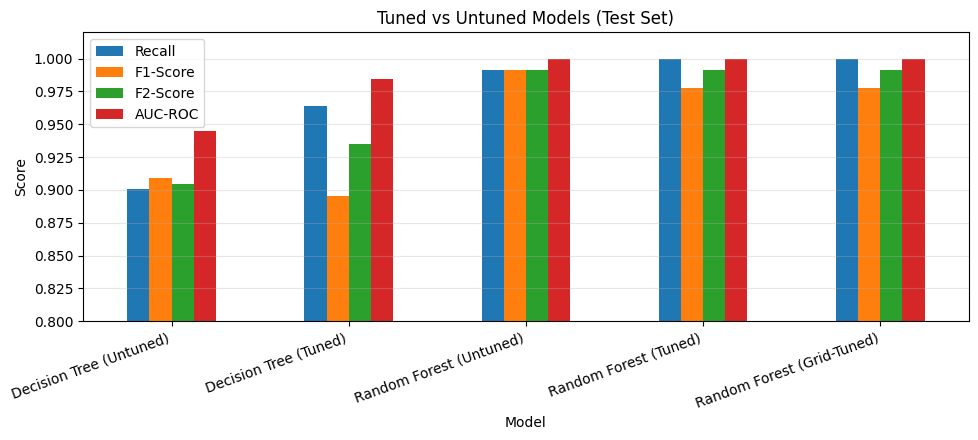

In [28]:
results_df = pd.DataFrame(model_results)

tuning_names = [
    'Decision Tree (Untuned)', 'Decision Tree (Tuned)',
    'Random Forest (Untuned)', 'Random Forest (Tuned)',
    f'{best_family} (Grid-Tuned)'
]
tuning_compare = results_df[results_df['Model'].isin(tuning_names)]
tuning_compare = tuning_compare.set_index('Model').loc[tuning_names].reset_index()
display(tuning_compare.round(4))

tuning_compare.set_index('Model')[['Recall', 'F1-Score', 'F2-Score', 'AUC-ROC']].plot(kind='bar', figsize=(10, 4.5), ylim=(0.8, 1.02))
plt.ylabel('Score')
plt.title('Tuned vs Untuned Models (Test Set)')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**📝 Interpretation:** Tuning helps both families. Decision Tree: F2 0.904 → 0.935, FN 11 → 4 (but FP 9 → 21). Random Forest: F2 stays ≈ 0.991, FN 1 → 0 (FP 1 → 5). Tuning for F2 deliberately trades some precision for fewer missed high-risk customers; the Grid-Tuned forest performs the same as the Randomized one.

## Part G: Model Evaluation & ROC Analysis

### Step 23 - ROC Curve for All Models

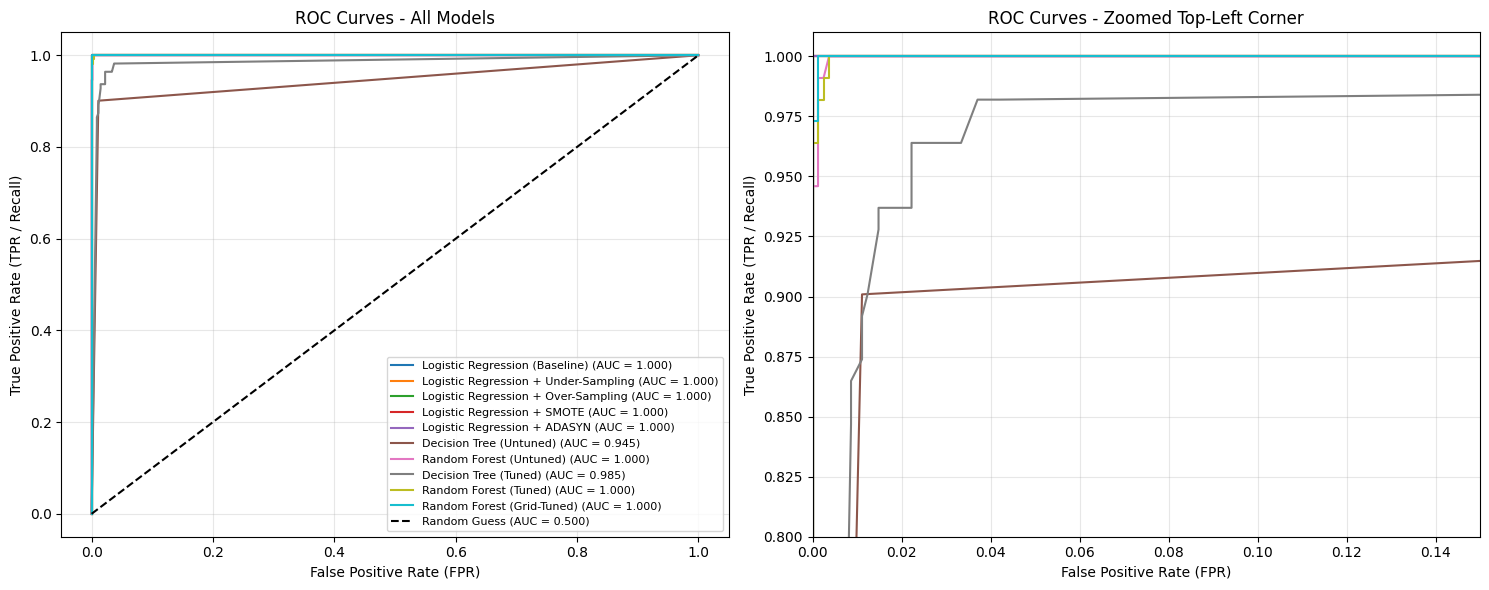

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, zoom in zip(axes, [False, True]):
    for model_name, prob in roc_store.items():
        fpr, tpr, _ = roc_curve(y_test, prob)
        ax.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc_score(y_test, prob):.3f})")
    if not zoom:
        ax.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.500)')
        ax.set_title('ROC Curves - All Models')
    else:
        ax.set_xlim(0, 0.15)
        ax.set_ylim(0.8, 1.01)
        ax.set_title('ROC Curves - Zoomed Top-Left Corner')
    ax.set_xlabel('False Positive Rate (FPR)')
    ax.set_ylabel('True Positive Rate (TPR / Recall)')
    ax.grid(alpha=0.3)

axes[0].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

**📝 Interpretation:** The curves of all Logistic Regression variants and the forests hug the top-left corner (AUC ≈ 1.0). Only the Decision Trees fall behind (AUC 0.945 untuned, 0.985 tuned); the zoomed panel shows their curves bending away at an FPR of 1-4%.

### Step 24 - Compute and Compare AUC-ROC Scores

,Model,AUC-ROC
0,Logistic Regression (Baseline),1.0000
1,Logistic Regression + Under-Sampling,1.0000
2,Logistic Regression + Over-Sampling,1.0000
3,Logistic Regression + SMOTE,1.0000
4,Logistic Regression + ADASYN,1.0000
5,Random Forest (Grid-Tuned),1.0000
6,Random Forest (Tuned),0.9999
7,Random Forest (Untuned),0.9999
8,Decision Tree (Tuned),0.9847
9,Decision Tree (Untuned),0.9449


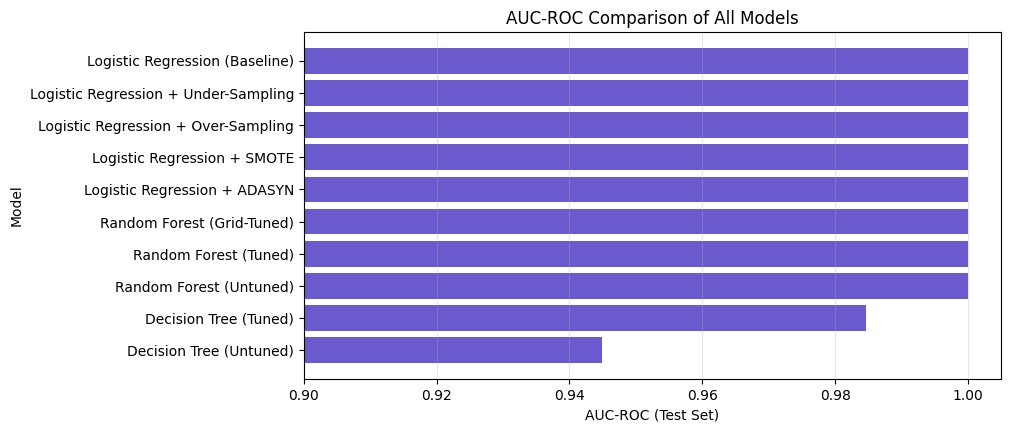

In [30]:
results_df = pd.DataFrame(model_results)

auc_table = results_df[['Model', 'AUC-ROC']].sort_values('AUC-ROC', ascending=False).reset_index(drop=True)
display(auc_table.round(4))

plt.figure(figsize=(9, 4.5))
plt.barh(auc_table['Model'], auc_table['AUC-ROC'], color='slateblue')
plt.gca().invert_yaxis()
plt.xlim(0.9, 1.005)
plt.xlabel('AUC-ROC (Test Set)')
plt.ylabel('Model')
plt.title('AUC-ROC Comparison of All Models')
plt.grid(axis='x', alpha=0.3)
plt.show()

**📝 Interpretation:** Five Logistic Regression models and the Grid-Tuned Random Forest reach AUC-ROC = 1.000 on the test set (other forests 0.9999), the tuned Decision Tree 0.985 and the untuned one 0.945. At this level AUC cannot rank the top models, so the final choice uses the recall-weighted CV F2.

### Step 25 - Select the Best Final Model (Business Requirement: Minimize False Negatives)

In [31]:
# Candidates (unfitted pipelines that operate on the prepared features)
final_candidates = {
    'Logistic Regression (Baseline)': Pipeline([
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    f'Logistic Regression + {best_sampler_name}': Pipeline([
        ('sampler', clone(samplers[best_sampler_name])),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Decision Tree (Tuned)': clone(dt_random.best_estimator_),
    'Random Forest (Tuned)': clone(rf_random.best_estimator_),
    f'{best_family} (Grid-Tuned)': clone(grid_search.best_estimator_)
}

# Cross-validated (TRAIN data) metrics → the selection signal; the test set only confirms it
cv_rows = []
for name, candidate in final_candidates.items():
    scores = cross_validate(candidate, X_train_prep, y_train, cv=cv_strategy, scoring=cv_scoring, n_jobs=-1)
    cv_rows.append({
        'Model': name,
        'CV Recall': scores['test_recall'].mean(),
        'CV Precision': scores['test_precision'].mean(),
        'CV F2': scores['test_f2'].mean(),
        'CV AUC-ROC': scores['test_roc_auc'].mean()
    })

cv_table = pd.DataFrame(cv_rows)
test_table = pd.DataFrame(model_results)[['Model', 'Recall', 'Precision', 'AUC-ROC', 'FP (Type-I)', 'FN (Type-II)']]
test_table.columns = ['Model', 'Test Recall', 'Test Precision', 'Test AUC-ROC', 'Test FP', 'Test FN']

final_table = cv_table.merge(test_table, on='Model').sort_values('CV F2', ascending=False).reset_index(drop=True)

final_model_name = final_table.loc[0, 'Model']
final_table['Selected'] = np.where(final_table['Model'] == final_model_name, '⭐', '')
display(final_table.round(4))

print(f"\n🏆 Final model (highest CV F2 = recall-weighted): {final_model_name}")

,Model,CV Recall,CV Precision,CV F2,CV AUC-ROC,Test Recall,Test Precision,Test AUC-ROC,Test FP,Test FN,Selected
0,Logistic Regression + Over-Sampling,0.9866,0.9551,0.9799,0.9993,1.000,0.9823,1.0000,2,0,⭐
1,Logistic Regression (Baseline),0.9732,0.9933,0.9770,0.9995,1.000,1.0000,1.0000,0,0,
2,Random Forest (Grid-Tuned),0.9642,0.9622,0.9637,0.9982,1.000,0.9569,1.0000,5,0,
3,Random Forest (Tuned),0.9642,0.9621,0.9637,0.9981,1.000,0.9569,0.9999,5,0,
4,Decision Tree (Tuned),0.9148,0.8091,0.8911,0.9721,0.964,0.8359,0.9847,21,4,



🏆 Final model (highest CV F2 = recall-weighted): Logistic Regression + Over-Sampling


**📝 Interpretation:** Ranked by CV F2 on training data (more reliable than a 920-row test split with zero errors), **Logistic Regression + Over-Sampling** comes first (CV F2 0.9799, CV recall 98.7%), just ahead of the plain baseline (0.9770, recall 97.3%) and clearly ahead of the forests (0.9637). On the test set it makes 0 false negatives and 2 false positives. The margin over the baseline is small, but the higher CV recall means fewer missed risky customers, which is the stated business priority.

## Part H: Final Analysis & Reporting

### Step 26 - Final Report

In [32]:
results_df = pd.DataFrame(model_results)
final_row = final_table.iloc[0]
final_test = results_df[results_df['Model'] == final_model_name].iloc[0]
baseline_test = results_df[results_df['Model'] == 'Logistic Regression (Baseline)'].iloc[0]

print("=" * 62)
print("📊 FINAL REPORT - RISK ALERT CLASSIFIER")
print("=" * 62)
print(f"🏆 Best model            : {final_model_name}")
print(f"🎯 Balancing technique   : {best_sampler_name} (best CV F2 among 4 techniques)")
print(f"📈 CV Recall / F2        : {final_row['CV Recall']:.4f} / {final_row['CV F2']:.4f}")
print(f"🧪 Test Recall / Precision: {final_test['Recall']:.4f} / {final_test['Precision']:.4f}")
print(f"🧪 Test F1 / AUC-ROC     : {final_test['F1-Score']:.4f} / {final_test['AUC-ROC']:.4f}")
print(f"⚠️  Missed high-risk (FN) : {int(final_test['FN (Type-II)'])}   | False alarms (FP): {int(final_test['FP (Type-I)'])}")
print("-" * 62)
print(f"Baseline LR (no balancing) → Test Recall {baseline_test['Recall']:.4f}, FN = {int(baseline_test['FN (Type-II)'])}, FP = {int(baseline_test['FP (Type-I)'])}")
print("=" * 62)

display(results_df.round(4).sort_values('F2-Score', ascending=False).reset_index(drop=True))

📊 FINAL REPORT - RISK ALERT CLASSIFIER
🏆 Best model            : Logistic Regression + Over-Sampling
🎯 Balancing technique   : Over-Sampling (best CV F2 among 4 techniques)
📈 CV Recall / F2        : 0.9866 / 0.9799
🧪 Test Recall / Precision: 1.0000 / 0.9823
🧪 Test F1 / AUC-ROC     : 0.9911 / 1.0000
⚠️  Missed high-risk (FN) : 0   | False alarms (FP): 2
--------------------------------------------------------------
Baseline LR (no balancing) → Test Recall 1.0000, FN = 0, FP = 0


,Model,Accuracy,Precision,Recall,F1-Score,F2-Score,AUC-ROC,FP (Type-I),FN (Type-II)
0,Logistic Regression (Baseline),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0,0
1,Logistic Regression + Over-Sampling,0.9978,0.9823,1.0000,0.9911,0.9964,1.0000,2,0
2,Logistic Regression + SMOTE,0.9978,0.9823,1.0000,0.9911,0.9964,1.0000,2,0
3,Logistic Regression + Under-Sampling,0.9967,0.9737,1.0000,0.9867,0.9946,1.0000,3,0
4,Logistic Regression + ADASYN,0.9967,0.9737,1.0000,0.9867,0.9946,1.0000,3,0
5,Random Forest (Grid-Tuned),0.9946,0.9569,1.0000,0.9780,0.9911,1.0000,5,0
6,Random Forest (Tuned),0.9946,0.9569,1.0000,0.9780,0.9911,0.9999,5,0
7,Random Forest (Untuned),0.9978,0.9910,0.9910,0.9910,0.9910,0.9999,1,1
8,Decision Tree (Tuned),0.9728,0.8359,0.9640,0.8954,0.9353,0.9847,21,4
9,Decision Tree (Untuned),0.9783,0.9174,0.9009,0.9091,0.9042,0.9449,9,11


**📝 Interpretation:** The winner is Logistic Regression + Over-Sampling: CV recall 0.9866, test recall 1.000, 0 missed high-risk customers and 2 false alarms. The baseline also has 0 errors on this particular test split, but its CV recall is lower (0.9732), so balancing is the safer choice for catching high-risk customers.

#### Business Interpretation of False Positives and False Negatives

- **False Negative (Type-II)** — a high-risk customer is missed: the bank loses money through an undetected default or fraud case. This is the costly error, so recall (and F2) drive the final choice.
- **False Positive (Type-I)** — a safe customer is flagged: the cost is an extra manual review or a short friction in the customer journey. It is cheap compared with a default, but too many of them overload the risk team, so precision is still monitored.

### Step 27 - Export the Final Pipeline and Deliverables

In [33]:
# Final deployable pipeline = preprocessing (KNN imputer + scaler + encoder) + [sampler] + model, fitted on RAW train data
winning_candidate = final_candidates[final_model_name]

final_pipeline = Pipeline(
    [('preprocessing', clone(preprocessor))] +
    [(step_name, clone(step)) for step_name, step in winning_candidate.steps]
)
final_pipeline.fit(X_train, y_train)

# Sanity check: the full pipeline on RAW test data must reproduce the stored test result
final_pred = final_pipeline.predict(X_test)
final_prob = final_pipeline.predict_proba(X_test)[:, 1]
stored = results_df[results_df['Model'] == final_model_name].iloc[0]

print("Pipeline steps :", [name for name, _ in final_pipeline.steps])
print("Test Recall    :", round(recall_score(y_test, final_pred), 4), "| stored:", round(stored['Recall'], 4))
print("Test AUC-ROC   :", round(roc_auc_score(y_test, final_prob), 4), "| stored:", round(stored['AUC-ROC'], 4))

Pipeline steps : ['preprocessing', 'sampler', 'model']
Test Recall    : 1.0 | stored: 1.0
Test AUC-ROC   : 1.0 | stored: 1.0


In [34]:
MODEL_DIR = Path('model')
MODEL_DIR.mkdir(exist_ok=True)

# 1) Export the pipeline as .pkl
with open(MODEL_DIR / 'risk_alert_pipeline.pkl', 'wb') as file:
    pickle.dump(final_pipeline, file)

# 2) Export metrics + feature lists (used later by the Streamlit app)
cm_final = confusion_matrix(y_test, final_pred)
metrics = {
    'model': final_model_name,
    'accuracy': float(accuracy_score(y_test, final_pred)),
    'precision': float(precision_score(y_test, final_pred, zero_division=0)),
    'recall': float(recall_score(y_test, final_pred)),
    'f1_score': float(f1_score(y_test, final_pred)),
    'f2_score': float(fbeta_score(y_test, final_pred, beta=2)),
    'roc_auc': float(roc_auc_score(y_test, final_prob)),
    'confusion_matrix': cm_final.tolist(),
    'train_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'target': TARGET
}
(MODEL_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=4))

print("Pipeline exported successfully →", MODEL_DIR / 'risk_alert_pipeline.pkl')
print("Metrics exported successfully  →", MODEL_DIR / 'metrics.json')

Pipeline exported successfully → model\risk_alert_pipeline.pkl
Metrics exported successfully  → model\metrics.json


In [35]:
# Reload the .pkl and predict a brand-new customer (credit_score & region left empty on purpose → imputers handle it)
with open(MODEL_DIR / 'risk_alert_pipeline.pkl', 'rb') as file:
    loaded_pipeline = pickle.load(file)

new_customer = pd.DataFrame({
    'age': [34],
    'annual_income_inr': [28000],
    'credit_score': [np.nan],
    'credit_utilization_ratio': [0.82],
    'missed_payments_12m': [5],
    'avg_late_payment_days': [21.5],
    'monthly_transaction_count': [70],
    'monthly_spend_inr': [18000],
    'cash_advance_count_6m': [3],
    'complaints_last_6m': [2],
    'failed_login_attempts_3m': [6],
    'account_tenure_months': [40],
    'debt_balance_inr': [90000],
    'gender': ['Male'],
    'region': [np.nan],
    'employment_type': ['Unemployed']
})[numeric_features + categorical_features]

risk_probability = loaded_pipeline.predict_proba(new_customer)[0, 1]
risk_label = 'HIGH RISK ⚠️' if loaded_pipeline.predict(new_customer)[0] == 1 else 'LOW RISK ✅'

print(f"Predicted Risk Status : {risk_label}")
print(f"High-Risk Probability : {risk_probability:.1%}")
print("Reloaded pipeline matches original:", np.array_equal(loaded_pipeline.predict(X_test), final_pred))

Predicted Risk Status : HIGH RISK ⚠️
High-Risk Probability : 100.0%
Reloaded pipeline matches original: True


**📝 Interpretation:** The full pipeline (KNN imputer + scaler + encoder + over-sampler + Logistic Regression) reproduces the stored test results from **raw** data, is saved to `model/risk_alert_pipeline.pkl` and reloads identically. A new customer with an empty `credit_score` and `region` is still scored, because the imputers run at prediction time. The over-sampler is active only while fitting, so predictions are unaffected by it.

#### Final Conclusions and Recommendations

- **Best model:** Logistic Regression + Over-Sampling (inside an imblearn Pipeline with KNN imputation, scaling and one-hot encoding). It has the highest cross-validated F2 (0.9799), CV recall of 98.7%, and on the test set 0 missed high-risk customers and 2 false alarms.
- **Imbalance handling:** all four techniques raised CV recall (97.3% → 98.4-98.9%) at the cost of precision (99.3% → 93.1-96.3%). Over-Sampling and SMOTE gave the best balance; Under-Sampling and ADASYN produced the most false alarms.
- **Model comparison:** the single Decision Tree overfits (train F1 1.00 vs test 0.91). Random Forest generalises well (CV F2 0.964), but the simple linear model is better still because the risk signal in this dataset is almost linear. Tuning improved both tree models, mainly by cutting false negatives.
- **Recommendation 1:** deploy the exported pipeline in a Streamlit app (`streamlit run app.py`) and show the probability next to the label, so analysts can review borderline customers first.
- **Recommendation 2:** if the bank wants even fewer missed customers, lower the decision threshold below 0.5 and re-check the false-alarm volume.
- **Recommendation 3:** the near-perfect scores suggest clean, possibly synthetic labels. Validate on fresh real data before relying on them, expect lower numbers in production, and keep the Random Forest as a challenger model.
- **Limitations:** the test set has only 111 high-risk customers, so results should be read with the cross-validation figures. SMOTE and ADASYN interpolate on one-hot columns; `SMOTENC` would be the stricter choice for mixed data.